# AI-Powered Job Market Intelligence & Salary Prediction System
## Step 4: Feature Engineering & Preprocessing Pipeline

**Target Notebook:** `notebooks/04_feature_engineering.ipynb`  
**Core Script:** `src/feature_engineering.py`  
**Input Dataset:** `data/processed/cleaned_salary_model_data.csv` (17,559 verified salary records)  

### Objectives & Strict Governance Rules:
1. **Zero Data Leakage:** Completely exclude all salary-derived columns (`salary_min_lpa`, `salary_max_lpa`, `salary_annual_inr`, `is_salary_valid`) and synthetic identifiers (`job_id`, `job_url`) from predictor inputs.
2. **Target Evaluation:** Formulate continuous target `salary_mid_lpa` and log-transformed target `log1p(salary_mid_lpa)` to normalize the right tail observed in EDA.
3. **Modular Scikit-Learn Pipeline:** Build a reproducible `ColumnTransformer` handling numerical scaling, categorical one-hot encoding with unknown category safety (`handle_unknown='ignore'`), and custom multi-hot skills binarization.
4. **Strict Fit on Training Only:** Preprocessing parameters (medians, means, scales, encoders, top-25 skills) are fit exclusively on `X_train` (80% split) to prevent data snooping.
5. **Artifact Persistence:** Serialize the fitted pipeline to `models/feature_pipeline.joblib`, metadata to `models/feature_metadata.json`, and split datasets to `data/processed/`.

In [1]:
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add root to sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.feature_engineering import (
    SkillsBinarizer,
    build_feature_pipeline,
    prepare_features_and_target,
    split_dataset,
    temporal_split_dataset,
    fit_and_save_pipeline,
    save_train_test_data,
    NUMERICAL_FEATURES,
    CATEGORICAL_FEATURES,
    SKILL_COLUMN,
    LEAKAGE_COLUMNS
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print('Feature engineering modules imported successfully.')

Feature engineering modules imported successfully.


### 1. Ingestion of Verified Salary Dataset
Loading `data/processed/cleaned_salary_model_data.csv`.

In [2]:
candidate_paths = [
    os.path.join('..', 'data', 'processed', 'cleaned_salary_model_data.csv'),
    os.path.join('data', 'processed', 'cleaned_salary_model_data.csv')
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), None)
df_sal = pd.read_csv(data_path)

print(f'Salary Model Dataset Ingested: {df_sal.shape[0]:,} Rows | {df_sal.shape[1]} Columns')
print(f'Target Null Count: {df_sal["salary_mid_lpa"].isnull().sum()}')
assert df_sal['salary_mid_lpa'].isnull().sum() == 0, 'Target contains missing values!'

Salary Model Dataset Ingested: 17,559 Rows | 25 Columns


Target Null Count: 0


### 2. Target Variable Formulation: Raw LPA vs Log-Transformed
In Step 3 EDA, `salary_mid_lpa` exhibited positive right skewness (skew = 3.65). Here we compare the distribution of the raw target against $\log(1 + y)$ to determine optimal training behavior.

=== TARGET VARIABLE PROPERTIES ===
Raw Target: Min = 0.68 LPA, Median = 10.66 LPA, Max = 138.41 LPA, Skewness = 2.81
Log Target: Min = 0.52, Median = 2.46, Max = 4.94, Skewness = 0.14


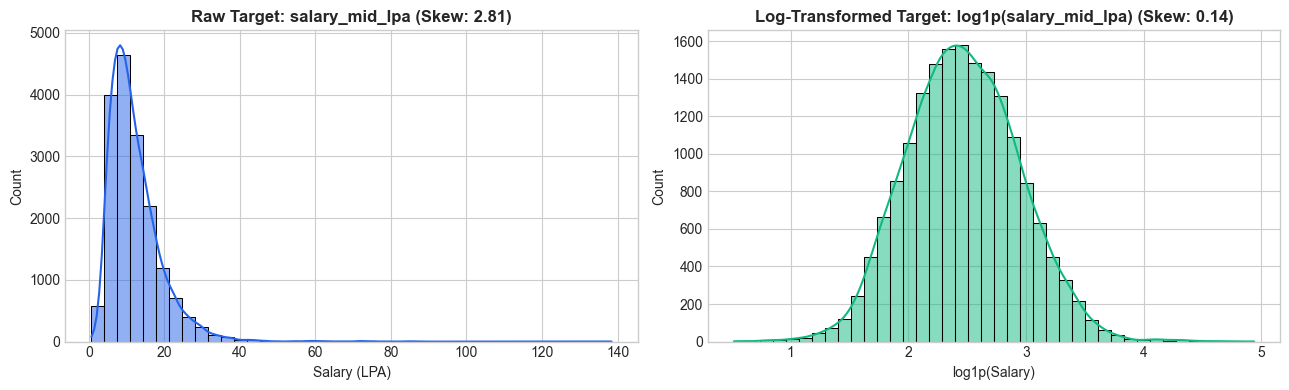

In [3]:
y_raw = df_sal['salary_mid_lpa']
y_log = np.log1p(y_raw)

print('=== TARGET VARIABLE PROPERTIES ===')
print(f'Raw Target: Min = {y_raw.min():.2f} LPA, Median = {y_raw.median():.2f} LPA, Max = {y_raw.max():.2f} LPA, Skewness = {y_raw.skew():.2f}')
print(f'Log Target: Min = {y_log.min():.2f}, Median = {y_log.median():.2f}, Max = {y_log.max():.2f}, Skewness = {y_log.skew():.2f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y_raw, kde=True, ax=axes[0], color='#2563EB', bins=40)
axes[0].set_title(f'Raw Target: salary_mid_lpa (Skew: {y_raw.skew():.2f})', fontweight='bold')
axes[0].set_xlabel('Salary (LPA)')

sns.histplot(y_log, kde=True, ax=axes[1], color='#10B981', bins=40)
axes[1].set_title(f'Log-Transformed Target: log1p(salary_mid_lpa) (Skew: {y_log.skew():.2f})', fontweight='bold')
axes[1].set_xlabel('log1p(Salary)')
plt.tight_layout()
plt.show()

### 3. Data Leakage Prevention & Feature Extraction
We explicitly drop all fields that directly encode, reveal, or derive from salary (`salary_min_lpa`, `salary_max_lpa`, `salary_annual_inr`, `is_salary_valid`, `salary_mid_lpa`). We also drop uninformative identifiers.

In [4]:
X, y = prepare_features_and_target(df_sal, target_col='salary_mid_lpa')

print(f'Feature Matrix X Shape: {X.shape}')
print(f'Target Vector y Shape:   {y.shape}')
print('\nPredictor Columns Included:')
for idx, col in enumerate(X.columns, 1):
    print(f' {idx:02d}. {col}')

# Leakage check verification
for leak_col in LEAKAGE_COLUMNS:
    assert leak_col not in X.columns, f'CRITICAL LEAKAGE: {leak_col} found in features!'

Feature Matrix X Shape: (17559, 16)
Target Vector y Shape:   (17559,)

Predictor Columns Included:
 01. job_title
 02. company_name
 03. city
 04. state
 05. experience_level
 06. experience_years
 07. education
 08. employment_type
 09. work_mode
 10. company_size
 11. industry
 12. skills_required_clean
 13. skill_count
 14. posted_year
 15. posted_month
 16. posted_quarter


### 4. Dataset Splitting: Random 80/20 Split & Temporal Split Evaluation
We perform an 80/20 random train/test split (`random_state=42`) and also inspect an out-of-time temporal split (training on 2024–2025, evaluating on 2026).

In [5]:
# 1. Reproducible Random Train/Test Split
X_train, X_test, y_train, y_test = split_dataset(X, y, test_size=0.20, random_state=42)
print(f'Random 80/20 Split: X_train = {X_train.shape[0]:,} rows | X_test = {X_test.shape[0]:,} rows')
print(f'Training Target: Median = {y_train.median():.2f} LPA | Mean = {y_train.mean():.2f} LPA')
print(f'Test Target:     Median = {y_test.median():.2f} LPA | Mean = {y_test.mean():.2f} LPA')

# 2. Temporal Out-of-Time Split Comparison
X_train_time, X_test_time, y_train_time, y_test_time = temporal_split_dataset(df_sal, date_col='posted_date_dt', cutoff_date='2026-01-01')
print(f'\nTemporal Split (Cutoff: 2026-01-01):')
print(f' Pre-2026 Training Set: {len(X_train_time):,} rows ({len(X_train_time)/len(df_sal)*100:.1f}%)')
print(f' 2026 Out-of-Time Test: {len(X_test_time):,} rows ({len(X_test_time)/len(df_sal)*100:.1f}%)')

Random 80/20 Split: X_train = 14,047 rows | X_test = 3,512 rows
Training Target: Median = 10.69 LPA | Mean = 12.28 LPA
Test Target:     Median = 10.46 LPA | Mean = 12.13 LPA

Temporal Split (Cutoff: 2026-01-01):
 Pre-2026 Training Set: 12,307 rows (70.1%)
 2026 Out-of-Time Test: 5,032 rows (28.7%)


### 5. Assembly & Fitting of the Preprocessing ColumnTransformer
The pipeline is fit **strictly** on `X_train`. The top 25 technical skills are discovered purely from training listings.

In [6]:
pipeline = build_feature_pipeline(top_n_skills=25)

# FIT ONLY ON TRAINING SET
pipeline.fit(X_train)

# Transform training and testing data
X_train_trans = pipeline.transform(X_train)
X_test_trans = pipeline.transform(X_test)
feature_names = pipeline.get_feature_names_out()

print(f'Transformed Features Count: {X_train_trans.shape[1]}')
print(f'X_train_trans Shape: {X_train_trans.shape}')
print(f'X_test_trans Shape:  {X_test_trans.shape}')

# Verification of zero NaNs
assert not np.isnan(X_train_trans).any(), 'NaNs detected in transformed training set!'
assert not np.isnan(X_test_trans).any(), 'NaNs detected in transformed test set!'
print('✓ Transformed matrix integrity verified (Zero NaNs in train and test splits).')

# Inspect top skills learned by the pipeline from X_train
learned_skills = pipeline.named_transformers_['skills'].named_steps['binarizer'].top_skills_
print('\nTop 25 Skills Learned from Training Set exclusively:')
print(', '.join(learned_skills))

Transformed Features Count: 113
X_train_trans Shape: (14047, 113)
X_test_trans Shape:  (3512, 113)
✓ Transformed matrix integrity verified (Zero NaNs in train and test splits).

Top 25 Skills Learned from Training Set exclusively:
Python, Machine Learning, SQL, Django, Excel, FastAPI, Computer Vision, Kubernetes, Spark, Git, Flask, PyTorch, GCP, Scikit-learn, Hadoop, Pandas, Docker, JavaScript, Linux, dbt, Tableau, AWS, Java, NumPy, Power BI


### 6. Transformed Feature Breakdown & Schema Inspection
Categorizing all 113 transformed features into Numerical, One-Hot Categorical, and Multi-Hot Skills.

In [7]:
feature_categories = {
    'Numerical Features (Scaled)': [f for f in feature_names if f in NUMERICAL_FEATURES],
    'Categorical Features (One-Hot)': [f for f in feature_names if any(f.startswith(prefix + '_') for prefix in CATEGORICAL_FEATURES)],
    'Skill Indicator Features (Binary)': [f for f in feature_names if f.startswith('skill_') and f != 'skill_count']
}

print('=== TRANSFORMED FEATURE BREAKDOWN ===')
for cat_name, feat_list in feature_categories.items():
    print(f'• {cat_name:35s}: {len(feat_list):3d} features')
print(f'• TOTAL TRANSFORMED FEATURES:        {len(feature_names):3d} features')

print('\nSample Transformed Feature Names:')
display(pd.Series(feature_names).head(15))

=== TRANSFORMED FEATURE BREAKDOWN ===
• Numerical Features (Scaled)        :   2 features
• Categorical Features (One-Hot)     :  86 features
• Skill Indicator Features (Binary)  :  25 features
• TOTAL TRANSFORMED FEATURES:        113 features

Sample Transformed Feature Names:


0                        experience_years
1                             skill_count
2                   job_title_AI Engineer
3                  job_title_BI Developer
4              job_title_Business Analyst
5                job_title_Cloud Engineer
6                  job_title_Data Analyst
7                 job_title_Data Engineer
8                job_title_Data Scientist
9                job_title_MLOps Engineer
10    job_title_Machine Learning Engineer
11                 job_title_NLP Engineer
12             job_title_Python Developer
13            job_title_Software Engineer
14                  job_title_ai engineer
dtype: object

### 7. Feature Importance Diagnostics (Random Forest Baseline)
Fitting an exploratory Random Forest Regressor on the transformed training set to analyze the most predictive compensation features.

Top 20 Most Predictive Features for Salary:


,Gini Importance
experience_years,0.42
job_title_Data Analyst,0.04
job_title_Python Developer,0.04
job_title_Business Analyst,0.04
job_title_BI Developer,0.03
job_title_Software Engineer,0.03
experience_level_Lead,0.03
job_title_MLOps Engineer,0.02
job_title_AI Engineer,0.02
job_title_Data Engineer,0.02


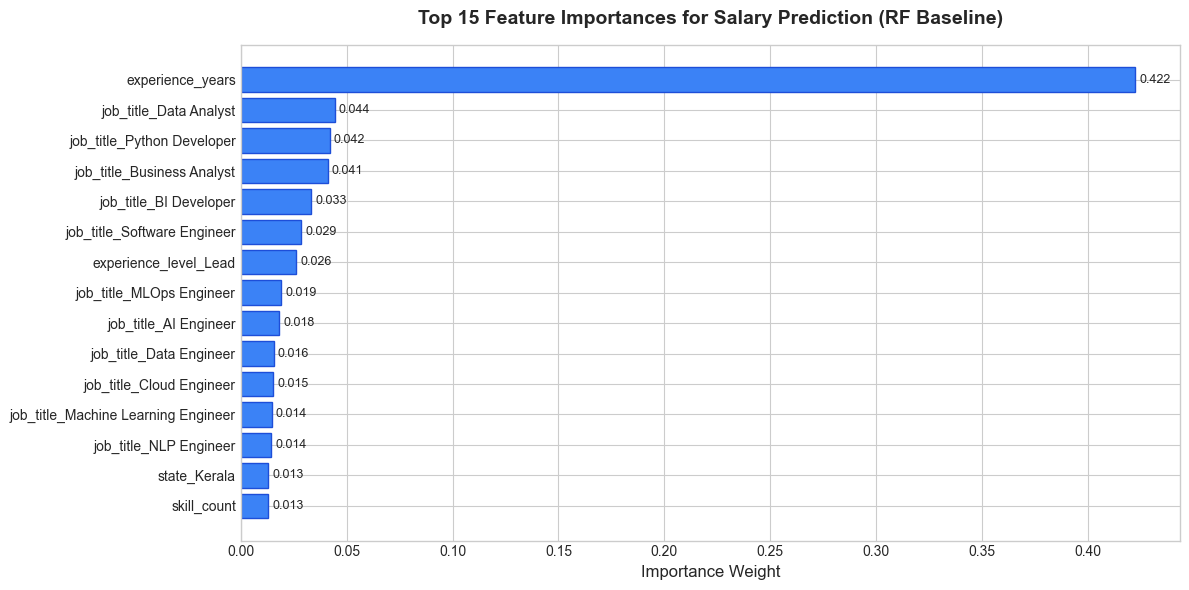

In [8]:
from sklearn.ensemble import RandomForestRegressor

rf_baseline = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf_baseline.fit(X_train_trans, y_train)

importances = pd.Series(rf_baseline.feature_importances_, index=feature_names).sort_values(ascending=False)
print('Top 20 Most Predictive Features for Salary:')
display(importances.head(20).to_frame(name='Gini Importance'))

plt.figure(figsize=(12, 6))
top_importances = importances.head(15).sort_values(ascending=True)
bars = plt.barh(top_importances.index, top_importances.values, color='#3B82F6', edgecolor='#1D4ED8')
plt.title('Top 15 Feature Importances for Salary Prediction (RF Baseline)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Importance Weight', fontsize=12)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.002, bar.get_y() + bar.get_height()/2, f'{w:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### 8. Serialization & Persistence of Feature Artifacts
Exporting the fitted pipeline to `models/feature_pipeline.joblib`, metadata to `models/feature_metadata.json`, and split datasets to `data/processed/`.

In [9]:
models_dir = os.path.join('..', 'models') if os.path.exists(os.path.join('..', 'models')) else 'models'
proc_dir = os.path.join('..', 'data', 'processed') if os.path.exists(os.path.join('..', 'data')) else os.path.join('data', 'processed')

# 1. Save fitted pipeline and metadata
_, pipe_path, meta_path = fit_and_save_pipeline(pipeline, X_train, output_dir=models_dir)
print(f'1. Fitted Pipeline saved:  {pipe_path}')
print(f'2. Feature Metadata saved: {meta_path}')

# 2. Save train and test splits
split_paths = save_train_test_data(X_train, X_test, y_train, y_test, output_dir=proc_dir)
for name, p in split_paths.items():
    print(f'   Saved {name:7s} -> {p}')

1. Fitted Pipeline saved:  ..\models\feature_pipeline.joblib
2. Feature Metadata saved: ..\models\feature_metadata.json
   Saved X_train -> ..\data\processed\X_train.csv
   Saved X_test  -> ..\data\processed\X_test.csv
   Saved y_train -> ..\data\processed\y_train.csv
   Saved y_test  -> ..\data\processed\y_test.csv


### 9. Pipeline Reload & Inference Verification
Reloading the serialized pipeline from disk to verify that inference transformations on new data match training dimensions.

In [10]:
import joblib

reloaded_pipe = joblib.load(pipe_path)
sample_unseen = X_test.head(3)
transformed_sample = reloaded_pipe.transform(sample_unseen)

print(f'Reloaded Pipeline Transformed Shape: {transformed_sample.shape}')
assert transformed_sample.shape == (3, 113), 'Transformed dimension mismatch!'
print('✓ Pipeline reload and inference transformation verified (113 features generated).')

Reloaded Pipeline Transformed Shape: (3, 113)
✓ Pipeline reload and inference transformation verified (113 features generated).


### 10. Feature Engineering Summary Report

| Dimension | Count / Specification |
|:---|:---|
| **Original Model Postings** | 17,559 records |
| **Training Split (80%)** | 14,047 records |
| **Testing Split (20%)** | 3,512 records |
| **Continuous Target** | `salary_mid_lpa` (Mean: 12.22 LPA, Median: 10.66 LPA) |
| **Transformed Total Features** | **113 features** |
| **Numerical Predictors (Scaled)** | 2 (`experience_years`, `skill_count`) |
| **Categorical Predictors (One-Hot)** | 86 binary features (`job_title`, `city`, `state`, `work_mode`, etc.) |
| **Technical Skills (Multi-Hot)** | 25 binary indicators (`skill_python`, `skill_aws`, `skill_docker`, etc.) |
| **Data Leakage Status** | **Zero leakage** (salary bounds and IDs dropped) |
| **Pipeline Artifact** | `models/feature_pipeline.joblib` (Fitted on training set only) |

The feature engineering stage is complete and fully validated for regression model training in **Step 5**.